# Task 3 y Task 4 — Recomendación de camas y ola epidémica

Se usa el simulador validado en `task1_2.ipynb` (`simulador.py`) y las fórmulas de `colas.py`.

**Grupo 10:** $\lambda = 3.8$ pacientes/día, $\mu = 0.25$ por día, $c = 17$ camas actuales, $k_{off} = 5$, $T_b = 7$ días.

Metas de la directora:

- Sin espera: probabilidad de desvío $B \le 2\%$.
- Con espera: tiempo medio de espera $W_q \le 6$ horas.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import simulador
from colas import erlang_b, mmc

LAM, MU, C_ACTUAL = 3.8, 0.25, 17
K_OFF, TB = 5, 7
HORAS = 24
META_B, META_WQ = 0.02, 6 / HORAS
CALENTAMIENTO, HORIZONTE, N_REP = 200, 5200, 30

## Task 3.1. Número de camas

### Mínimo de camas según la teoría

Se busca el menor $c$ que cumple cada meta: $B(c,a) \le 0.02$ con Erlang B y $W_q \le 6$ h con Erlang C. El factor `f_wq` multiplica $W_q$ y permite usar la aproximación de Allen y Cunneen, $f = (1 + C_S^2)/2$.

In [2]:
def camas_bloqueo(lam, mu):
    """Menor c con B(c, lam/mu) <= META_B."""
    c = 1
    while erlang_b(c, lam / mu) > META_B:
        c += 1
    return c


def camas_espera(lam, mu, f_wq=1.0):
    """Menor c estable con f_wq · Wq(M/M/c) <= META_WQ."""
    c = int(lam / mu) + 1
    while f_wq * mmc(lam, mu, c)["Wq"] > META_WQ:
        c += 1
    return c


print(f"{'c':>3}{'B (%)':>9}{'Wq (h)':>9}")
for c in range(17, 26):
    print(f"{c:>3}{erlang_b(c, LAM / MU) * 100:9.2f}{mmc(LAM, MU, c)['Wq'] * HORAS:9.2f}")
C_B, C_W = camas_bloqueo(LAM, MU), camas_espera(LAM, MU)
print(f"Mínimo sin espera: {C_B} camas. Mínimo con espera: {C_W} camas.")

  c    B (%)   Wq (h)
 17    11.88    29.87
 18     9.11    13.44
 19     6.80     6.75
 20     4.91     3.54
 21     3.43     1.89
 22     2.32     1.01
 23     1.51     0.53
 24     0.95     0.28
 25     0.57     0.14
Mínimo sin espera: 23 camas. Mínimo con espera: 20 camas.


**RESULTADOS**

- **Sin espera:** se necesitan **23 camas** ($B = 1.51\%$); con 22, $B = 2.32\%$.
- **Con espera:** se necesitan **20 camas** ($W_q = 3.54$ h); con 19, $W_q = 6.75$ h.

Con las 17 camas actuales no se cumple ninguna de las dos metas.

### Verificación con simulación

Se simula cada variante con el mínimo teórico y con una cama menos (30 réplicas, mismo calentamiento y horizonte del Task 1.4).

In [3]:
def verificar(variante, c, semilla, estancia=None):
    """Imprime la medida de la meta con su IC del 95% para c camas."""
    r, _ = simulador.replicas(LAM, MU, c, HORIZONTE, CALENTAMIENTO, semilla, variante, N_REP,
                              estancia=estancia)
    if variante == "perdida":
        m, (lo, hi), meta, u = r["prob_bloqueo"]["media"], r["prob_bloqueo"]["ic95"], META_B, 100
        nombre = "B (%)"
    else:
        m, (lo, hi), meta, u = r["Wq"]["media"], r["Wq"]["ic95"], META_WQ, HORAS
        nombre = "Wq (h)"
    print(f"{variante:<8} c = {c}: {nombre} = {m * u:.2f}, IC95 = ({lo * u:.2f}, {hi * u:.2f}), "
          f"cumple: {'sí' if hi <= meta else ('no' if lo > meta else 'dudoso')}")


for c in (C_B - 1, C_B):
    verificar("perdida", c, 600 + c)
for c in (C_W - 1, C_W):
    verificar("espera", c, 700 + c)

perdida  c = 22: B (%) = 2.30, IC95 = (2.18, 2.42), cumple: no


perdida  c = 23: B (%) = 1.49, IC95 = (1.40, 1.58), cumple: sí


espera   c = 19: Wq (h) = 6.98, IC95 = (6.56, 7.40), cumple: no


espera   c = 20: Wq (h) = 3.52, IC95 = (3.29, 3.74), cumple: sí


**RESULTADOS**

La simulación confirma ambos mínimos: con 23 camas, $B = 1.49\%$ (IC: 1.40 a 1.58), y con 22 el IC queda por encima del 2%. Con 20 camas, $W_q = 3.52$ h (IC: 3.29 a 3.74), y con 19 el IC queda por encima de 6 h.

### Robustez

Escenarios:

1. Estancia media 25% más larga: $\mu = 0.2$.
2. Llegadas 15% mayores: $\lambda = 4.37$.
3. Estancia lognormal con $C_S = 2$: para la meta de desvío se usa Erlang B, que depende solo de la media de la estancia. Para la meta de espera se usa Allen y Cunneen ($f = 2.5$), y se verifica con simulación porque en el Task 2.2 esa aproximación sobreestimó la espera.

In [4]:
escenarios = {
    "Base": (LAM, MU, 1.0),
    "(i) Estancia +25%": (LAM, MU / 1.25, 1.0),
    "(ii) Llegadas +15%": (LAM * 1.15, MU, 1.0),
    "(iii) C_S = 2": (LAM, MU, 2.5),
}
print(f"{'Escenario':<20}{'Sin espera (B <= 2%)':>22}{'Con espera (Wq <= 6 h)':>24}")
for nombre, (lam, mu, f) in escenarios.items():
    print(f"{nombre:<20}{camas_bloqueo(lam, mu):>22}{camas_espera(lam, mu, f):>24}")

Escenario             Sin espera (B <= 2%)  Con espera (Wq <= 6 h)
Base                                    23                      20
(i) Estancia +25%                       27                      24
(ii) Llegadas +15%                      25                      22
(iii) C_S = 2                           23                      21


In [5]:
lognormal = simulador.estancia_lognormal(MU, 2)
c_ln = camas_espera(LAM, MU, 2.5)
for c in (c_ln - 1, c_ln):
    verificar("espera", c, 800 + c, estancia=lognormal)
verificar("perdida", C_B, 900, estancia=lognormal)

espera   c = 20: Wq (h) = 6.25, IC95 = (5.52, 6.98), cumple: dudoso


espera   c = 21: Wq (h) = 2.88, IC95 = (2.52, 3.24), cumple: sí


perdida  c = 23: B (%) = 1.41, IC95 = (1.30, 1.52), cumple: sí


**RESULTADOS**

| Escenario | Sin espera ($B \le 2\%$) | Con espera ($W_q \le 6$ h) |
|---|---|---|
| Base | 23 | 20 |
| (i) Estancia +25% | 27 | 24 |
| (ii) Llegadas +15% | 25 | 22 |
| (iii) $C_S = 2$ | 23 | 21 |

En el escenario (iii), la simulación confirma ambos valores: con 21 camas $W_q = 2.88$ h (IC: 2.52 a 3.24); con 20 camas el IC (5.52 a 6.98 h) contiene la meta, así que 20 no es suficiente con seguridad. Sin espera, 23 camas dan $B = 1.41\%$ con estancia lognormal.

**Por qué la meta de desvío cambia menos:** en la variante sin espera nadie hace fila, y la probabilidad de desvío depende solo de la carga promedio $a = \lambda/\mu$, es decir, de la estancia media y no de su forma. En la variante con espera, la variabilidad de la estancia agrupa las altas y hace crecer la fila (Task 2.2), por lo que se necesita una cama más con $C_S = 2$.

### Recomendación

Se recomienda **operar con espera y mantener 22 camas**:

- Cumple la meta de espera con margen: $W_q \approx 1$ h, contra 6 h permitidas.
- Sigue cumpliendo con 15% más de llegadas (necesita 22) y con estancias más variables (necesita 21). Solo falla si la estancia media sube 25% (necesitaría 24).
- Con espera no se pierde a ningún paciente. La variante sin espera necesitaría 23 camas en la situación actual y 27 en el peor escenario, y aun así desviaría hasta al 2% de los pacientes.
- Si el hospital decidiera desviar, 22 camas darían $B = 2.3\%$, apenas por encima de la meta.

### Cierre de $k_{off}$ camas con la recomendación

Se usa la recomendación de 22 camas (ver la recomendación más arriba). Durante el cierre quedan $22 - 5 = 17$ camas. Se simula la variante sin espera con el cierre entre los días 300 y 307, en 1000 réplicas, y se mide la fracción de pacientes desviados entre los que llegan durante el cierre.

In [6]:
C_REC = 22
T0 = 300
N_CIERRE = 1000
r_c, d_c = simulador.replicas(LAM, MU, C_REC, T0 + TB + 1, CALENTAMIENTO, 1000, "perdida", N_CIERRE,
                              cierre=(T0, T0 + TB, K_OFF))
b_cierre = d_c["prob_bloqueo_cierre"]
media = b_cierre.mean()
margen = 1.96 * b_cierre.std(ddof=1) / np.sqrt(N_CIERRE)
print(f"B durante el cierre (simulado) = {media:.2%}, IC95 = ({media - margen:.2%}, {media + margen:.2%})")
print(f"B con {C_REC - K_OFF} camas en régimen estacionario (Erlang B) = {erlang_b(C_REC - K_OFF, LAM / MU):.2%}")
print(f"B fuera del cierre con {C_REC} camas (Erlang B) = {erlang_b(C_REC, LAM / MU):.2%}")
print(f"Pacientes desviados esperados durante el cierre = {LAM * TB * media:.1f}")
print(f"Camas temporales para cumplir cada meta durante el cierre: "
      f"sin espera {camas_bloqueo(LAM, MU) - (C_REC - K_OFF)}, con espera {camas_espera(LAM, MU) - (C_REC - K_OFF)}")

B durante el cierre (simulado) = 13.50%, IC95 = (12.70%, 14.30%)
B con 17 camas en régimen estacionario (Erlang B) = 11.88%
B fuera del cierre con 22 camas (Erlang B) = 2.32%
Pacientes desviados esperados durante el cierre = 3.6
Camas temporales para cumplir cada meta durante el cierre: sin espera 6, con espera 3


**RESULTADOS**

- Durante el cierre se desvía al **13.5%** de los pacientes (IC: 12.7% a 14.3%), cerca de 3.6 pacientes en la semana. Es más que el 11.9% que daría Erlang B con 17 camas, porque al iniciar el cierre muchas veces ya hay 17 o más camas ocupadas y nadie entra hasta que se liberan.
- Con 22 camas el desvío normal es 2.3%; el cierre lo multiplica casi por 6.

La recomendación **no protege** al hospital durante el cierre: con 17 camas el hospital vuelve a la situación actual. **Decisión de contingencia sugerida:** asegurar 3 camas temporales (por ejemplo, un convenio con otro hospital o camas de intermedios equipadas) mientras dure el cierre. Así se mantienen 20 camas, el mínimo para la meta de espera. Para cumplir la meta de desvío harían falta 6.

## Task 4.1. Ola epidémica

### Modelo SIR

$$\frac{dS}{dt} = -\beta\frac{SI}{N}, \qquad \frac{dI}{dt} = \beta\frac{SI}{N} - \gamma I, \qquad \frac{dR}{dt} = \gamma I$$

con $N = 500\,000$, $\gamma = 0.2$ por día (tasa de recuperación), $I(0) = 100$, $R(0) = 0$ y $\beta = 0.30 + 0.02\,(9 \bmod 4) = 0.32$ por día (grupo 10). Se integra con Runge-Kutta de cuarto orden con paso $h = 0.01$ días.

Una fracción $p_h = 0.0002$ de los nuevos infectados requiere UCI:

$$\lambda_{epi}(t) = p_h\,\beta\,\frac{S(t)I(t)}{N}, \qquad \lambda(t) = \lambda + \lambda_{epi}(t)$$

Pico: día 58.9, lam_epi = 1.729 pacientes/día (46% de la tasa base)
Pacientes UCI adicionales en 200 días: 64.2


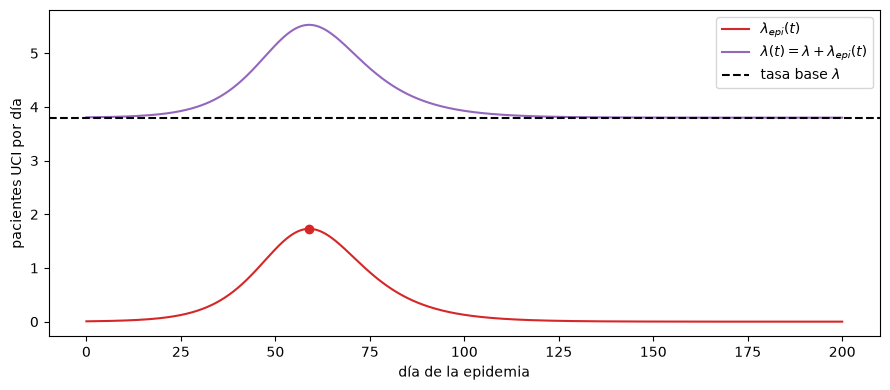

In [7]:
N_POB, GAMMA, BETA, P_H = 500_000, 0.2, 0.32, 0.0002
DIAS_EPI, H = 200, 0.01


def sir(x):
    """Campo del modelo SIR para el estado x = (S, I, R)."""
    s, i, _ = x
    contagios = BETA * s * i / N_POB
    return np.array([-contagios, contagios - GAMMA * i, GAMMA * i])


def rk4(f, x0, h, n):
    """Integra x' = f(x) con Runge-Kutta 4 durante n pasos y devuelve la trayectoria."""
    X = np.empty((n + 1, len(x0)))
    X[0] = x0
    for k in range(n):
        x = X[k]
        k1 = f(x)
        k2 = f(x + h / 2 * k1)
        k3 = f(x + h / 2 * k2)
        k4 = f(x + h * k3)
        X[k + 1] = x + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return X


n_pasos = int(DIAS_EPI / H)
t_epi = np.arange(n_pasos + 1) * H
X = rk4(sir, np.array([N_POB - 100, 100, 0.0]), H, n_pasos)
lam_epi = P_H * BETA * X[:, 0] * X[:, 1] / N_POB

k_pico = lam_epi.argmax()
print(f"Pico: día {t_epi[k_pico]:.1f}, lam_epi = {lam_epi[k_pico]:.3f} pacientes/día "
      f"({lam_epi[k_pico] / LAM:.0%} de la tasa base)")
print(f"Pacientes UCI adicionales en 200 días: {np.trapezoid(lam_epi, t_epi):.1f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t_epi, lam_epi, color="tab:red", label=r"$\lambda_{epi}(t)$")
ax.plot(t_epi, LAM + lam_epi, color="tab:purple", label=r"$\lambda(t) = \lambda + \lambda_{epi}(t)$")
ax.axhline(LAM, color="k", ls="--", label=r"tasa base $\lambda$")
ax.plot(t_epi[k_pico], lam_epi[k_pico], "o", color="tab:red")
ax.set_xlabel("día de la epidemia")
ax.set_ylabel("pacientes UCI por día")
ax.legend()
fig.tight_layout()
fig.savefig("figuras/ola.png", dpi=150)
plt.show()

**RESULTADOS**

El pico de la ola ocurre el **día 58.9**, con $\lambda_{epi} = 1.73$ pacientes UCI/día adicionales, un 46% más que la tasa base. En total, la epidemia agrega unos 64 pacientes UCI en 200 días.

### Simulación con tasa variable

Las llegadas se generan por adelgazamiento: se proponen llegadas con tasa constante $\lambda_{max} = \max_t \lambda(t)$ y cada una se acepta con probabilidad $\lambda(t)/\lambda_{max}$.

- Se simula la variante sin espera con las 22 camas recomendadas y 100 réplicas.
- Los primeros 100 días tienen la tasa base (calentamiento) y la epidemia empieza en el día 100.
- **Ola:** días en que $\lambda_{epi}(t)$ es al menos el 10% de su pico.
- El bloqueo en función del tiempo es la fracción de llegadas desviadas en cada día, sumando todas las réplicas.

In [8]:
T_INICIO = 100
N_OLA = 100
m_ola = lam_epi >= 0.1 * lam_epi[k_pico]
ola = (T_INICIO + t_epi[m_ola][0], T_INICIO + t_epi[m_ola][-1])
lam_max = LAM + lam_epi.max()


def tasa(t):
    """Tasa de llegadas lam(t): base antes de T_INICIO y base + lam_epi después."""
    return LAM + np.interp(t - T_INICIO, t_epi, lam_epi, left=0.0, right=0.0)


def simular_ola(c, semilla):
    """Corre N_OLA réplicas sin espera con c camas; devuelve las corridas con historial."""
    semillas = np.random.SeedSequence(semilla).spawn(N_OLA)
    return [simulador.simular(LAM, MU, c, T_INICIO + DIAS_EPI, T_INICIO, s, "perdida", tasa=tasa,
                              tasa_max=lam_max, historial=True) for s in semillas]


def desviados_ola(corridas):
    """Por réplica: (pacientes desviados, fracción desviada) entre las llegadas de la ola."""
    datos = []
    for r in corridas:
        en_ola = (r["t_llegadas"] >= ola[0]) & (r["t_llegadas"] < ola[1])
        desv = r["desviado"][en_ola].sum()
        datos.append((desv, desv / en_ola.sum()))
    return np.array(datos)


def ic95(x):
    """Media e IC del 95% (t de Student) de un arreglo de réplicas."""
    from scipy import stats
    m = x.mean()
    e = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return m, m - e, m + e


C_REC = 22
corridas = simular_ola(C_REC, 2000)
d = desviados_ola(corridas)
print(f"Ola: días {ola[0] - T_INICIO:.1f} a {ola[1] - T_INICIO:.1f} de la epidemia")
print("Desviados durante la ola: {:.1f} pacientes, IC95 = ({:.1f}, {:.1f})".format(*ic95(d[:, 0])))
print("Fracción desviada durante la ola: {:.2%}, IC95 = ({:.2%}, {:.2%})".format(*ic95(d[:, 1])))
print(f"Referencia sin epidemia (Erlang B, {C_REC} camas): {erlang_b(C_REC, LAM / MU):.2%}")

Ola: días 27.9 a 96.4 de la epidemia
Desviados durante la ola: 28.1 pacientes, IC95 = (25.6, 30.6)
Fracción desviada durante la ola: 8.60%, IC95 = (7.90%, 9.31%)
Referencia sin epidemia (Erlang B, 22 camas): 2.32%


**RESULTADOS**

- La ola dura de los días 27.9 a 96.4 de la epidemia (unos 69 días).
- Con 22 camas, durante la ola se desvía a **28.1 pacientes** (IC: 25.6 a 30.6), es decir, al **8.6%** de los que llegan (IC: 7.9% a 9.3%). Sin epidemia se desviaría al 2.3%.

Bloqueo máximo: 17.0% en el día 58 de la epidemia


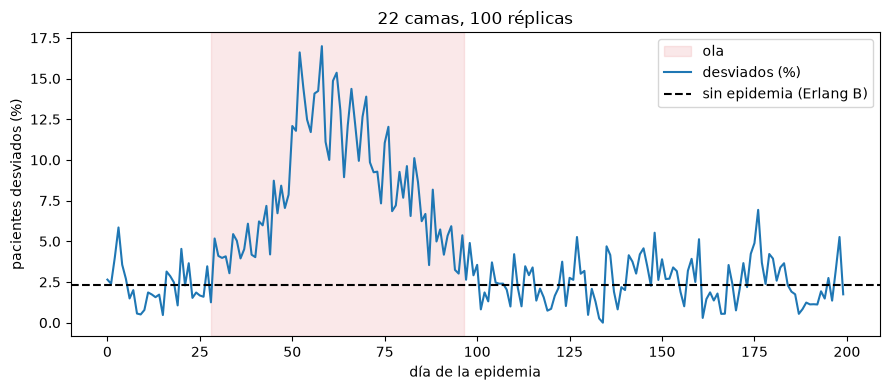

In [9]:
dias = np.arange(T_INICIO, T_INICIO + DIAS_EPI)
llegadas_dia = np.zeros(len(dias))
desviados_dia = np.zeros(len(dias))
for r in corridas:
    k = np.floor(r["t_llegadas"]).astype(int) - T_INICIO
    ok = (k >= 0) & (k < len(dias))
    np.add.at(llegadas_dia, k[ok], 1)
    np.add.at(desviados_dia, k[ok], r["desviado"][ok])
b_dia = desviados_dia / llegadas_dia
k_max = b_dia.argmax()
print(f"Bloqueo máximo: {b_dia[k_max]:.1%} en el día {k_max} de la epidemia")

fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(ola[0] - T_INICIO, ola[1] - T_INICIO, color="tab:red", alpha=0.1, label="ola")
ax.plot(dias - T_INICIO, b_dia * 100, color="tab:blue", label="desviados (%)")
ax.axhline(erlang_b(C_REC, LAM / MU) * 100, color="k", ls="--", label="sin epidemia (Erlang B)")
ax.set_xlabel("día de la epidemia")
ax.set_ylabel("pacientes desviados (%)")
ax.set_title(f"{C_REC} camas, {N_OLA} réplicas")
ax.legend()
fig.tight_layout()
fig.savefig("figuras/bloqueo_ola.png", dpi=150)
plt.show()

**RESULTADOS**

El bloqueo sigue la forma de la ola: llega a un máximo del 17% cerca del día 58 y vuelve al nivel normal (cerca del 2.3%) hacia el día 100. Fuera de la ola, las variaciones diarias son ruido de simulación.

### Camas de contingencia

Se agregan camas, una a la vez, hasta que la fracción media de pacientes desviados durante la ola no supere el 5%.

In [10]:
c = C_REC
while True:
    m, lo, hi = ic95(desviados_ola(simular_ola(c, 3000 + c))[:, 1])
    print(f"c = {c}: fracción desviada en la ola = {m:.2%}, IC95 = ({lo:.2%}, {hi:.2%})")
    if m <= 0.05:
        break
    c += 1
print(f"Camas de contingencia necesarias: {c - C_REC}")

c = 22: fracción desviada en la ola = 8.48%, IC95 = (7.83%, 9.13%)


c = 23: fracción desviada en la ola = 6.95%, IC95 = (6.28%, 7.62%)


c = 24: fracción desviada en la ola = 4.84%, IC95 = (4.29%, 5.39%)
Camas de contingencia necesarias: 2


**RESULTADOS**

| Camas | Fracción desviada en la ola | IC95 |
|---|---|---|
| 22 | 8.48% | 7.83% a 9.13% |
| 23 | 6.95% | 6.28% a 7.62% |
| 24 | 4.84% | 4.29% a 5.39% |

Con **2 camas de contingencia** (24 en total), la fracción media desviada baja a 4.84%. El IC aún incluye el 5%, así que, si se quiere seguridad estadística, conviene una tercera cama.

**Cambio en la recomendación:** se mantienen las 22 camas permanentes, pero la reserva de contingencia sube a **3 camas** activables durante una ola. Esa reserva también cubre el cierre de camas (Task 3.1c) y el escenario de estancia más larga (24 camas).